In [1]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
from tqdm import tqdm
import os
import warnings

# === 可选：忽略弃用警告（你的 geopandas 版本较老）
warnings.filterwarnings("ignore", category=DeprecationWarning)

# === 启用 tqdm 进度条支持 pandas
tqdm.pandas()

# === 文件路径设置 ===
csv_path = r"F:\TUB\greenlandProject\ne_10m_admin_0_countries\daqucsv.csv"
shp_path = r"F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenland_boundary.shp"
output_dir = r"F:\TUB\greenlandProject\ne_10m_admin_0_countries"

# === 读取 CSV 文件并转换为 GeoDataFrame ===
df = pd.read_csv(csv_path)
geometry = [Point(lon, lat) for lon, lat in zip(df['longitude'], df['latitude'])]
gdf_points = gpd.GeoDataFrame(df, geometry=geometry, crs="EPSG:4326")

# === 读取格陵兰边界 SHP 文件 ===
greenland = gpd.read_file(shp_path)
if greenland.crs != "EPSG:4326":
    greenland = greenland.to_crs("EPSG:4326")

# === 合并边界为一个几何体（并可选简化） ===
print("合并格陵兰边界中...")
greenland_union = greenland.unary_union.simplify(0.01, preserve_topology=True)  # 速度与精度平衡可调

# === 使用 tqdm 判断点是否在边界内 ===
print("判断每个点是否在格陵兰边界内...")
gdf_points['in_greenland'] = gdf_points['geometry'].progress_apply(lambda geom: geom.within(greenland_union))

# === 过滤出格陵兰内的点 ===
points_in_greenland = gdf_points[gdf_points['in_greenland']]

# === 输出文件路径 ===
csv_filename = os.path.basename(csv_path).replace(".csv", "_GreenlandBoundry.csv")
output_path = os.path.join(output_dir, csv_filename)

# === 保存结果（去除 geometry 和中间列） ===
points_in_greenland.drop(columns=['geometry', 'in_greenland']).to_csv(output_path, index=False)

# === 输出信息 ===
print(f"\n原始总点数: {len(df)}")
print(f"保留在格陵兰内的点数: {len(points_in_greenland)}")
print(f"筛选结果已保存到: {output_path}")


合并格陵兰边界中...
判断每个点是否在格陵兰边界内...


100%|██████████| 82482/82482 [08:31<00:00, 161.37it/s]



原始总点数: 82482
保留在格陵兰内的点数: 65472
筛选结果已保存到: F:\TUB\greenlandProject\ne_10m_admin_0_countries\daqucsv_GreenlandBoundry.csv


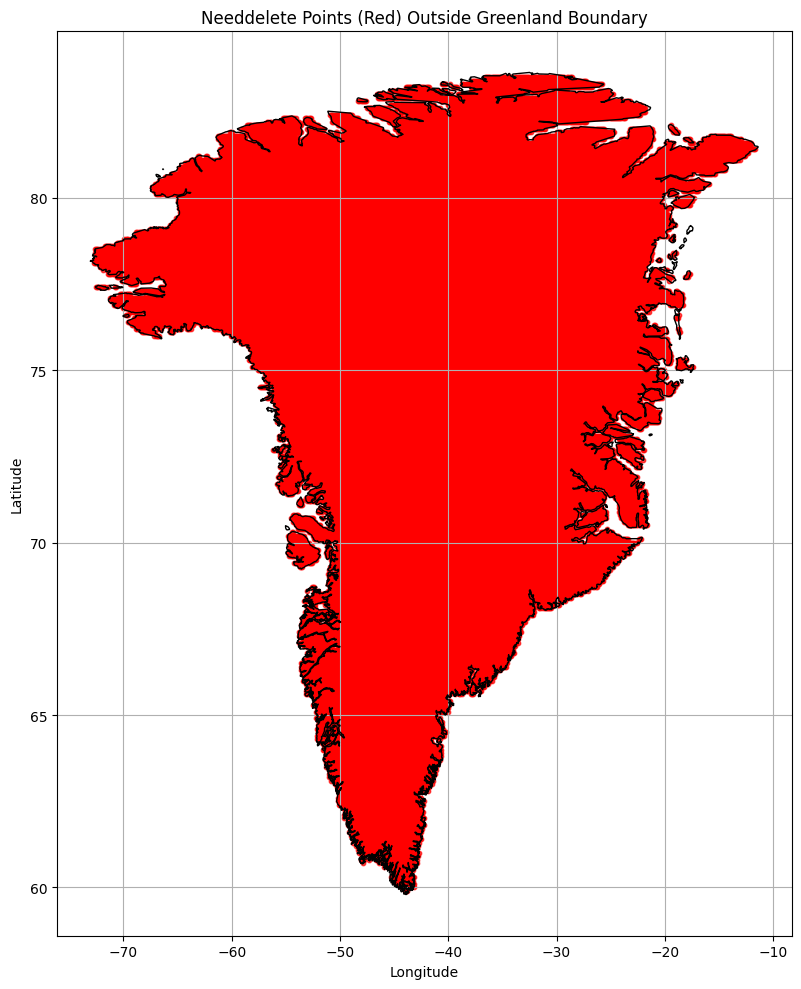

In [2]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import matplotlib.pyplot as plt
import os

# === 路径设置 ===
needdelete_csv = r"F:\TUB\greenlandProject\ne_10m_admin_0_countries\GreenlandBoundry.csv"
greenland_shp = r"F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenland_boundary.shp"

# === 读取Needdelete点 ===
df_needdelete = pd.read_csv(needdelete_csv)
geometry_needdelete = [Point(lon, lat) for lon, lat in zip(df_needdelete['longitude'], df_needdelete['latitude'])]
gdf_needdelete = gpd.GeoDataFrame(df_needdelete, geometry=geometry_needdelete, crs="EPSG:4326")

# === 读取格陵兰边界 ===
greenland = gpd.read_file(greenland_shp)
if greenland.crs != "EPSG:4326":
    greenland = greenland.to_crs("EPSG:4326")

# === 绘图 ===
fig, ax = plt.subplots(figsize=(10, 10))
greenland.boundary.plot(ax=ax, edgecolor='black', linewidth=1)
gdf_needdelete.plot(ax=ax, color='red', markersize=10, alpha=0.7)

# === 图形美化 ===
ax.set_title("Needdelete Points (Red) Outside Greenland Boundary")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
import os
import pandas as pd

folder_path = r"F:\TUB\greenlandProject\ERA5LAND\MonthlyFeatures\prediction"
columns_to_keep = ['latitude', 'longitude', 'altitude_last_valid', 'albedo']

for filename in os.listdir(folder_path):
    if filename.endswith(".csv"):
        full_path = os.path.join(folder_path, filename)
        df = pd.read_csv(full_path)

        # 只保留存在的指定列
        cols_in_df = [col for col in columns_to_keep if col in df.columns]
        df_new = df[cols_in_df]

        # 构造新文件名
        name_part, ext = os.path.splitext(filename)
        new_filename = f"{name_part}_area{ext}"
        new_path = os.path.join(folder_path, new_filename)

        # 保存新文件
        df_new.to_csv(new_path, index=False)

        print(f"已生成文件: {new_filename}, 行数: {len(df_new)}")


In [ ]:
#根据shp提取出来csv中的点-------------------------过滤原来的完整文件------------新文件只有Greenland区域的经纬高----和反照率
import os
import pandas as pd

# 目标文件夹和边界点文件
folder_path = r"F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenlandAlbedo"
boundary_file = r"F:\TUB\greenlandProject\ne_10m_admin_0_countries\GreenlandBoundry.csv"

# 读取边界点（latitude, longitude）
boundary_df = pd.read_csv(boundary_file, usecols=['latitude', 'longitude'])

# 为快速查找，转换成集合，方便做坐标匹配（浮点数直接匹配可能有误差，需谨慎）
boundary_coords = set(zip(boundary_df['latitude'], boundary_df['longitude']))

for filename in os.listdir(folder_path):
    if filename.endswith('.csv'):
        full_path = os.path.join(folder_path, filename)
        df = pd.read_csv(full_path)

        # 过滤，只保留坐标在boundary_coords集合中的行
        # 注意：这里是精确匹配纬度经度的浮点数
        mask = df.apply(lambda row: (row['latitude'], row['longitude']) in boundary_coords, axis=1)
        df_filtered = df[mask]

        # 生成新文件名，防止覆盖
        name_part, ext = os.path.splitext(filename)
        new_filename = f"{name_part}_albedo{ext}"
        new_path = os.path.join(folder_path, new_filename)

        # 保存过滤后的数据
        df_filtered.to_csv(new_path, index=False)

        print(f"已生成文件: {new_filename}, 保留行数: {len(df_filtered)}")
